# Axial buckling of cylinders with integral blade stringers: Card and Jones (1966)

M. F. Card and R. M. Jones, *Experimental and theoretical results for buckling of eccentrically stiffened cylinders*, NASA TN D-3639, October 1966 (NTRS 19660027866).

Card and Jones tested in axial compression twelve longitudinally stiffened aluminium cylinders, in pairs with the stiffeners outside (external) or inside (internal) the skin. Cylinders 1 to 4 have integral rectangular (blade) stringers machined from 3/8 in plate, the configuration of this notebook; cylinders 5 to 12 have riveted Z stringers. For each cylinder their Table I gives the experimental buckling load and number of circumferential waves, and the buckling load of a smeared-stiffener theory for clamped and for simply supported ends (Galerkin solutions with a membrane pre-buckling state, Appendix A and Block, Card and Mikulas, NASA TN D-2960, 1965). The externally stiffened cylinders carried more than twice the load of the internally stiffened ones.

This notebook models cylinders 1 to 4 with `panels`, with the skin as curved panels between the stringers and each stringer as a flat plate strip, a `MultiDomain` assembly, and compares the linear buckling loads with the test and with the smeared theory. The same assembly is used for the vibration tests of Sewall and Naumann (1968) in `sewall1968_blade_cylinder_vibration.ipynb`, through the module `blade_cylinder_utils.py`.

In [1]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

import blade_cylinder_utils as bu
from blade_cylinder_utils import IN, LBF, PSI


def pct(value, ref):
    return 100*(value - ref)/ref


def markdown_table(header, rows):
    out = ['| ' + ' | '.join(header) + ' |', '|' + '---|'*len(header)]
    out += ['| ' + ' | '.join(str(c) for c in row) + ' |' for row in rows]
    return Markdown('\n'.join(out))

## Test data

Table I (p. 7) of the report, cylinders 1 to 4, all of 2024-T351 aluminium alloy with $E = 10.5 \times 10^3$ ksi and $\mu = 0.32$ (footnote of Table I): skin thickness $t$, length $L$, radius of the middle surface $R$, area of the stiffened cross-section $A_t$ (by weighing, p. 5), experimental buckling load $\bar{P}_e$, average stress $\bar{\sigma}_e$, experimental number of circumferential waves $n_e$, and the buckling loads per unit length of circumference $\bar{N} = \bar{P}/(2\pi R)$ of the test ($\bar{N}_e$) and of the theory for clamped ($\bar{N}_c$) and simply supported ($\bar{N}_s$) ends.

The headers of the columns $\bar{N}$ of Table I read kips/in. and MN/m, but the values are in lb/in and kN/m: for cylinder 1, $112.6$ kips $/(2\pi \times 9.55$ in$) = 1877$ lb/in, the printed value, and $1877$ lb/in $= 328.7$ kN/m, printed 329 (derived). The values in lb/in are used below.

Fig. 2(b) (p. 6) gives the stringer: width 0.097 in (0.246 cm), depth 0.33 in (0.84 cm) from the stringer tip to the skin surface opposite the stringer (see below), fillet radius 0.03 in (0.08 cm), spacing 1.00 in (2.54 cm); the number of stringers is not stated, $2\pi \times 9.55/1.00 = 60.0$ (derived), so 60.

In [2]:
E_KSI, NU = 10.5e3, 0.32
E = E_KSI*1e3*PSI
R_IN = 9.55
NSTIFF = 60
# Fig. 2(b) (p. 6): stringer width, total depth (tip to the skin surface
# opposite the stringer, skin included) and fillet radius, in
WIDTH, DEPTH, FILLET = 0.097, 0.33, 0.03
# Card and Jones (1966), Table I(a) (p. 7): side, t in, L in, A_t in^2, P_e kips,
# sigma_e ksi, n_e, N_e, N_c, N_s lb/in (headed kips/in.)
TABLE_I = {
    1: ('external', 0.0283, 38.00, 3.69, 112.6, 30.5, 6, 1877, 2036, 1145),
    2: ('internal', 0.0277, 38.00, 3.72, 48.0, 12.9, 6, 800, 997, 687),
    3: ('external', 0.0275, 23.75, 3.70, 127.2, 34.4, 7, 2120, 2595, 1326),
    4: ('internal', 0.0280, 23.75, 3.63, 58.0, 16.0, 6, 965, 1226, 722),
}
# Table I(b), SI: P_e kN, N_e, N_c, N_s kN/m (headed MN/m)
TABLE_I_SI = {1: (500, 329, 357, 200), 2: (214, 140, 175, 120),
              3: (566, 371, 454, 232), 4: (258, 169, 215, 127)}
print('E = %.1f ksi = %.1f GPa (Table I(b): 72 400 MN/m^2)' % (E_KSI, E/1e9))
rows = []
for cyl, (side, t, L, At, Pe, se, ne, Ne, Nc, Ns) in TABLE_I.items():
    rows.append([cyl, side, t, L, At, Pe, ne, Ne, Nc, Ns,
                 '%.0f (%d)' % (Pe*1e3/(2*np.pi*R_IN), Ne),
                 '%.1f (%d)' % (Ne*LBF/IN/1e3, TABLE_I_SI[cyl][1])])
display(markdown_table(['cyl.', 'stringers', 't, in', 'L, in', 'A_t, in^2', 'P_e, kips', 'n_e',
                        'N_e', 'N_c', 'N_s', 'P_e/(2 pi R), lb/in (N_e)', 'N_e, kN/m (SI table)'], rows))

E = 10500.0 ksi = 72.4 GPa (Table I(b): 72 400 MN/m^2)


| cyl. | stringers | t, in | L, in | A_t, in^2 | P_e, kips | n_e | N_e | N_c | N_s | P_e/(2 pi R), lb/in (N_e) | N_e, kN/m (SI table) |
|---|---|---|---|---|---|---|---|---|---|---|---|
| 1 | external | 0.0283 | 38.0 | 3.69 | 112.6 | 6 | 1877 | 2036 | 1145 | 1877 (1877) | 328.7 (329) |
| 2 | internal | 0.0277 | 38.0 | 3.72 | 48.0 | 6 | 800 | 997 | 687 | 800 (800) | 140.1 (140) |
| 3 | external | 0.0275 | 23.75 | 3.7 | 127.2 | 7 | 2120 | 2595 | 1326 | 2120 (2120) | 371.3 (371) |
| 4 | internal | 0.028 | 23.75 | 3.63 | 58.0 | 6 | 965 | 1226 | 722 | 967 (965) | 169.0 (169) |

**Datum of the stringer height.** In Fig. 2(b) the extension lines of the 0.33 in dimension run from the tip of the stringer to the surface of the skin opposite the stringer: 0.33 in is the total depth of the section, skin included. The stringer stands $0.33 - t$ above the skin surface, and its plate in the model, from the middle surface of the skin to the tip, has the width $h_b = 0.33 - t/2$ in. The bfsccylinder implementation of this case (`bfsccylinder/notebooks/card1966_stiffened_cylinder_buckling.ipynb`) reads the drawing in the same way.

Two checks of this reading follow. (1) The area: the skin, $2\pi R t$, plus 60 rectangles $0.097 \times (0.33 - t)$ in with two fillets each, $2 r_F^2 (1 - \pi/4)$, plus the four doubler plates of the two butt joints, $0.70 \times 0.020$ in each (p. 5), is 3 % to 6 % below the area $A_t$ of Table I, which was determined by weighing (p. 5; the rivets are not counted; 5 % to 7 % without the doublers, as in the bfsccylinder notebook). A stringer 0.33 in high above the skin surface would match $A_t$ within 2 %, but (2) the theory of Card and Jones decides: their simply supported $\bar{N}_s$ is the closed-form solution of Block, Card and Mikulas (1965, NASA TN D-2960, Eq. (15)) for stringers only, with the membrane pre-buckling state and the torsional stiffness $G_s J_s$ of the stringers ($J$ of a rectangle, symbol list of Card and Jones, p. 4). Evaluated below with the section of Fig. 2(b), it reproduces the four values $\bar{N}_s$ of Table I within 0.2 %, and with a stringer 0.33 in high above the skin surface it is up to 10 % higher: Card and Jones used the drawn section, not $A_t$, and so does the model.

In [3]:
def torsion_J(ts, h):
    # J of a rectangle ts x h (Card and Jones 1966, symbol list, p. 4)
    return ts**3*h*(1/3 - 64/np.pi**5*ts/h*np.tanh(np.pi*h/(2*ts)))


def section(t, side, hs, z0, plate=False, width=WIDTH):
    # stringer rectangle width x hs starting at z0 from the skin middle surface:
    # area, eccentricity, moment of inertia about the skin middle surface, J of the
    # rectangle or, with plate=True, of the Kirchhoff plate strip (4 D66 hs = G J)
    A, zc = width*hs, z0 + hs/2
    J = hs*width**3/3 if plate else torsion_J(width, hs)
    return A, (1 if side == 'external' else -1)*zc, width*hs**3/12 + A*zc**2, J


def nx_ss(t, L, As, zs, Is, J, nmax=40, mmax=6, nstiff=NSTIFF):
    # Block, Card and Mikulas (1965), Eq. (15), stringers only, isotropic skin and
    # stringers, simply supported, membrane pre-buckling state; minimum over (m, n), lb/in
    E_, G_ = E_KSI*1e3, E_KSI*1e3/(2*(1 + NU))
    ds = 2*np.pi*R_IN/nstiff
    Ex, D = E_*t/(1 - NU**2), E_*t**3/(12*(1 - NU**2))
    best = (np.inf, None)
    for m in range(1, mmax + 1):
        a = m*np.pi/L
        for n in range(nmax + 1):
            b = n/R_IN
            A11 = (Ex + E_*As/ds)*a**2 + G_*t*b**2
            A22 = Ex*b**2 + G_*t*a**2
            A12 = (NU*Ex + G_*t)*a*b
            A13 = NU*Ex/R_IN*a + E_*As*zs/ds*a**3
            A23 = Ex*b/R_IN
            A33 = D*(a**2 + b**2)**2 + E_*Is/ds*a**4 + G_*J/ds*a**2*b**2 + Ex/R_IN**2
            den = A11*A22 - A12**2
            N = (A33 + A23*(A12*A13 - A11*A23)/den + A13*(A12*A23 - A22*A13)/den)/a**2
            if N < best[0]:
                best = (N, (m, n))
    return best


A_F = 2*FILLET**2*(1 - np.pi/4)
rows, rows_ns = [], []
for cyl, (side, t, L, At, Pe, se, ne, Ne, Nc, Ns) in TABLE_I.items():
    A_str = NSTIFF*(WIDTH*(DEPTH - t) + A_F)
    A = 2*np.pi*R_IN*t + A_str + 4*0.70*0.020
    A_alt = 2*np.pi*R_IN*t + NSTIFF*(WIDTH*DEPTH + A_F) + 4*0.70*0.020
    rows.append([cyl, '%.3f' % (2*np.pi*R_IN*t), '%.3f' % A_str, '%.3f' % A, At,
                 '%+.1f%%' % pct(A, At), '%+.1f%%' % pct(A_alt, At)])
    out = [cyl, side, Ns]
    for hs, z0, plate in ((DEPTH - t, t/2, False), (DEPTH - t/2, 0., False),
                          (DEPTH - t/2, 0., True), (DEPTH, t/2, False)):
        N, mn = nx_ss(t, L, *section(t, side, hs, z0, plate))
        out.append('%.0f (%d, %d), %+.1f%%' % (N, *mn, pct(N, Ns)))
    rows_ns.append(out)
display(markdown_table(['cyl.', 'skin, in^2', 'stringers (0.33 - t), in^2', 'total with doublers, in^2',
                        'A_t, in^2', 'difference', 'difference with stringers 0.33 high'], rows))
display(markdown_table(['cyl.', 'stringers', 'N_s (Table I)', 'Eq. (15), Fig. 2(b): 0.33 - t on the skin',
                        'Eq. (15), plate of the model (0.33 - t/2 from the middle surface), J of the rectangle',
                        'Eq. (15), plate of the model, J = h_b t_b^3/3 of the plate strip',
                        'Eq. (15), 0.33 on the skin'], rows_ns))

| cyl. | skin, in^2 | stringers (0.33 - t), in^2 | total with doublers, in^2 | A_t, in^2 | difference | difference with stringers 0.33 high |
|---|---|---|---|---|---|---|
| 1 | 1.698 | 1.779 | 3.533 | 3.69 | -4.2% | +0.2% |
| 2 | 1.662 | 1.783 | 3.501 | 3.72 | -5.9% | -1.6% |
| 3 | 1.650 | 1.784 | 3.490 | 3.7 | -5.7% | -1.4% |
| 4 | 1.680 | 1.781 | 3.517 | 3.63 | -3.1% | +1.4% |

| cyl. | stringers | N_s (Table I) | Eq. (15), Fig. 2(b): 0.33 - t on the skin | Eq. (15), plate of the model (0.33 - t/2 from the middle surface), J of the rectangle | Eq. (15), plate of the model, J = h_b t_b^3/3 of the plate strip | Eq. (15), 0.33 on the skin |
|---|---|---|---|---|---|---|
| 1 | external | 1145 | 1144 (1, 6), -0.1% | 1157 (1, 6), +1.0% | 1186 (1, 6), +3.6% | 1221 (1, 6), +6.6% |
| 2 | internal | 687 | 687 (1, 5), +0.0% | 703 (1, 5), +2.3% | 723 (1, 5), +5.3% | 696 (1, 5), +1.4% |
| 3 | external | 1326 | 1328 (1, 7), +0.2% | 1343 (1, 7), +1.3% | 1383 (1, 7), +4.3% | 1460 (1, 7), +10.1% |
| 4 | internal | 722 | 723 (1, 6), +0.1% | 742 (1, 6), +2.8% | 771 (1, 6), +6.8% | 741 (1, 6), +2.6% |

## Model

**Discrete stringers** (see `bu.build_cylinder`). The skin between two stringers is a curved panel of the Sanders-Koiter cylindrical shell model (`cylshell_clpt_sanders`) and each stringer a flat plate strip normal to the skin, of thickness $t_b = 0.097$ in and width $h_b = 0.33 - t/2$ in, from the middle surface of the skin to the stringer tip (Fig. 2(b), see above), connected to the skin with the base-flange connection `'BFycte'` (displacements and rotation about the stringer axis continuous) and the skin panels to each other with `'SSycte'`, both imposed exactly with `conn_method='null-space'` (Castro and Donadon 2017, https://doi.org/10.1016/j.compstruct.2016.10.026). The blade stands inside or outside the skin according to the edge of the blade that is connected; the eccentricity of the stringers, the distance $\bar{z}$ of their centroid from the middle surface of the skin in the smeared theory, follows from this geometry. The blade overlaps the skin over $t/2$, in place of the two fillets that the plate strips do not represent: the plate area $0.097 (0.33 - t/2)$ is about 3 % larger than that of the drawn stringer with its fillets, $0.097 (0.33 - t) + 2 r_F^2 (1 - \pi/4)$ (derived). For cylinder 4, against the drawn rectangle, the plate from the middle surface has an area 4.6 % larger, its centroid $t/4$ closer to the skin, the same moment of inertia about the middle surface of the skin within $t_b (t/2)^3/3$, and, as a Kirchhoff plate strip, the twisting stiffness $4 D_{66} h_b = G h_b t_b^3/3$, 31 % above $G J$ of the drawn rectangle with the $J$ of Card and Jones (derived). Eq. (15) for the stringer of the model, with this twisting stiffness, is 3.6 % to 6.8 % above $\bar{N}_s$ of Table I; with the plate and $J$ of the rectangle it is 1.0 % to 2.8 % above (table above).

The stringers carry about half of the axial load, and the general instability of a stringer-stiffened cylinder bends them in their own plane, radially. The geometric stiffness of a plate model with the von Kármán strains contains the terms of the out-of-plane displacement only, $N_{xx} w_{,x}^2$, and would miss the destabilizing work of the stringer load $N_{xx} v_{,x}^2$ on the in-plane (radial) deflection of the blade; the blades are therefore modelled with `plate_clpt_gl`, whose Green-Lagrange membrane strains give the in-plane terms of the geometric stiffness too, with the same linear stiffness as `plate_clpt_donnell`.

**Symmetry.** The buckling mode of a cylinder with 60 identical, equally spaced stringers is close to $w \propto \cos n\theta$ times an axial shape; it is symmetric about two planes $\theta = 0$ and $\theta = \pi$ through the middle of a bay, and half of the cylinder, with $v = w_{,y} = 0$ on these planes, contains it for every $n$ (the half model is compared with the full cylinder in the notebook of Sewall and Naumann).

**Boundary conditions and pre-buckling state.** The test cylinders were potted at both ends in a low-temperature alloy, ground flat and parallel and loaded between the platens of a testing machine, with 1/4 in aluminium bulkheads held by the potting (p. 6). Four analyses are run:

| analysis | ends | pre-buckling state | function |
|---|---|---|---|
| clamped, linear | $u = v = w = w_{,x} = 0$ at $x = 0$; the same at $x = L$ with the uniform shortening $u = -\lambda\delta$ prescribed on skin and blades | linear static solution, with the bending of the skin near the ends | `bu.buckling_clamped` |
| SS, linear | $N_x = v = w = M_x = 0$ at both ends, equal and opposite end loads $E t \varepsilon$ (skin) and $E t_b \varepsilon$ (blades); one point $u = 0$ against the rigid translation | linear static solution | `bu.buckling_ss` |
| clamped, membrane | $u = v = w = w_{,x} = 0$ at both ends | membrane, $N_{xx} = -E t \varepsilon$ in the skin, $-E t_b \varepsilon$ in the blades | `bu.buckling_membrane` |
| SS, membrane | as SS, linear | membrane | `bu.buckling_membrane` |

The clamped and simply supported conditions are those of Card and Jones (p. 9 and 10), whose theory uses the membrane pre-buckling state; the clamped analysis with the linear pre-buckling state is closest to the test. The critical load $\bar{P}$ is $\lambda$ times the axial force of the reference state (for the prescribed shortening, the resultant of the reactions at $x = L$, `MultiDomain.reaction_resultant`), and $\bar{N} = \bar{P}/(2\pi R)$.

## Convergence

The number of Ritz terms is increased in four steps: $m_x$ along $x$ (skin and blades), $n_y$ across a full skin bay, $n_b$ across a blade. The table gives the critical $\bar{N}$ of each analysis and its change from the previous step; the last step is used in the comparisons.

In [4]:
LEVELS = [(10, 4, 4), (14, 6, 4), (18, 8, 5), (22, 10, 6)]
ANALYSES = {
    'clamped, linear': lambda *a: bu.buckling_clamped(*a),
    'SS, linear': lambda *a: bu.buckling_ss(*a),
    'clamped, membrane': lambda *a: bu.buckling_membrane(*a[:8], 'CC', *a[8:]),
    'SS, membrane': lambda *a: bu.buckling_membrane(*a[:8], 'SS', *a[8:]),
}
RES = {}
rows = []
for cyl, (side, t, L, *_) in TABLE_I.items():
    args = (R_IN*IN, t*IN, L*IN, E, NU, WIDTH*IN, (DEPTH - t/2)*IN, side)
    for name, func in ANALYSES.items():
        prev = None
        for i, (mx, ny, nyb) in enumerate(LEVELS):
            P, modes, md, skin, dt = func(*args, mx, ny, nyb)
            N = P/LBF/(2*np.pi*R_IN)
            RES[(cyl, name, i)] = (N, modes[0][1], modes[0][2], md if i == len(LEVELS) - 1 else None,
                                   skin, modes[0][3],
                                   [(lam/modes[0][0]*N, m, n) for lam, m, n, c in modes[:5]])
            rows.append([cyl, name, '%d, %d, %d' % (mx, ny, nyb), md.get_size(), '%.1f' % dt,
                         '%.0f' % N, '(%d, %d)' % modes[0][1:3],
                         '-' if prev is None else '%+.2f%%' % pct(N, prev)])
            prev = N
display(markdown_table(['cyl.', 'analysis', 'm_x, n_y, n_b', 'dofs', 'time, s', 'N, lb/in', '(m, n)',
                        'change'], rows))
FINAL = len(LEVELS) - 1

| cyl. | analysis | m_x, n_y, n_b | dofs | time, s | N, lb/in | (m, n) | change |
|---|---|---|---|---|---|---|---|
| 1 | clamped, linear | 10, 4, 4 | 7320 | 3.2 | 1803 | (2, 9) | - |
| 1 | clamped, linear | 14, 6, 4 | 12684 | 6.2 | 2018 | (1, 7) | +11.96% |
| 1 | clamped, linear | 18, 8, 5 | 21060 | 18.7 | 2027 | (1, 7) | +0.41% |
| 1 | clamped, linear | 22, 10, 6 | 31680 | 41.3 | 2029 | (1, 7) | +0.12% |
| 1 | SS, linear | 10, 4, 4 | 7320 | 2.8 | 1148 | (1, 6) | - |
| 1 | SS, linear | 14, 6, 4 | 12684 | 5.9 | 1150 | (1, 6) | +0.23% |
| 1 | SS, linear | 18, 8, 5 | 21060 | 16.5 | 1151 | (1, 6) | +0.09% |
| 1 | SS, linear | 22, 10, 6 | 31680 | 35.8 | 1151 | (1, 6) | -0.00% |
| 1 | clamped, membrane | 10, 4, 4 | 7320 | 1.9 | 2037 | (1, 7) | - |
| 1 | clamped, membrane | 14, 6, 4 | 12684 | 3.0 | 2031 | (1, 7) | -0.30% |
| 1 | clamped, membrane | 18, 8, 5 | 21060 | 7.0 | 2029 | (1, 7) | -0.09% |
| 1 | clamped, membrane | 22, 10, 6 | 31680 | 11.8 | 2028 | (1, 7) | -0.04% |
| 1 | SS, membrane | 10, 4, 4 | 7320 | 2.1 | 1140 | (1, 6) | - |
| 1 | SS, membrane | 14, 6, 4 | 12684 | 4.1 | 1139 | (1, 6) | -0.15% |
| 1 | SS, membrane | 18, 8, 5 | 21060 | 9.8 | 1137 | (1, 6) | -0.10% |
| 1 | SS, membrane | 22, 10, 6 | 31680 | 15.4 | 1136 | (1, 6) | -0.08% |
| 2 | clamped, linear | 10, 4, 4 | 7320 | 3.1 | 855 | (2, 8) | - |
| 2 | clamped, linear | 14, 6, 4 | 12684 | 5.9 | 991 | (2, 7) | +16.00% |
| 2 | clamped, linear | 18, 8, 5 | 21060 | 17.6 | 993 | (2, 7) | +0.20% |
| 2 | clamped, linear | 22, 10, 6 | 31680 | 37.3 | 993 | (2, 7) | -0.01% |
| 2 | SS, linear | 10, 4, 4 | 7320 | 2.7 | 665 | (1, 5) | - |
| 2 | SS, linear | 14, 6, 4 | 12684 | 5.9 | 667 | (1, 5) | +0.32% |
| 2 | SS, linear | 18, 8, 5 | 21060 | 16.9 | 668 | (1, 5) | +0.07% |
| 2 | SS, linear | 22, 10, 6 | 31680 | 34.2 | 668 | (1, 5) | -0.00% |
| 2 | clamped, membrane | 10, 4, 4 | 7320 | 1.8 | 993 | (2, 7) | - |
| 2 | clamped, membrane | 14, 6, 4 | 12684 | 2.9 | 990 | (2, 7) | -0.26% |
| 2 | clamped, membrane | 18, 8, 5 | 21060 | 6.8 | 990 | (2, 7) | -0.07% |
| 2 | clamped, membrane | 22, 10, 6 | 31680 | 11.6 | 989 | (2, 7) | -0.03% |
| 2 | SS, membrane | 10, 4, 4 | 7320 | 2.1 | 666 | (1, 5) | - |
| 2 | SS, membrane | 14, 6, 4 | 12684 | 3.9 | 665 | (1, 5) | -0.13% |
| 2 | SS, membrane | 18, 8, 5 | 21060 | 8.5 | 664 | (1, 5) | -0.10% |
| 2 | SS, membrane | 22, 10, 6 | 31680 | 16.7 | 664 | (1, 5) | -0.08% |
| 3 | clamped, linear | 10, 4, 4 | 7320 | 3.1 | 2631 | (1, 8) | - |
| 3 | clamped, linear | 14, 6, 4 | 12684 | 6.2 | 2626 | (1, 8) | -0.20% |
| 3 | clamped, linear | 18, 8, 5 | 21060 | 18.9 | 2628 | (1, 8) | +0.08% |
| 3 | clamped, linear | 22, 10, 6 | 31680 | 43.9 | 2627 | (1, 8) | -0.02% |
| 3 | SS, linear | 10, 4, 4 | 7320 | 2.7 | 1373 | (1, 7) | - |
| 3 | SS, linear | 14, 6, 4 | 12684 | 5.7 | 1373 | (1, 7) | -0.03% |
| 3 | SS, linear | 18, 8, 5 | 21060 | 15.2 | 1373 | (1, 7) | -0.03% |
| 3 | SS, linear | 22, 10, 6 | 31680 | 36.5 | 1372 | (1, 7) | -0.05% |
| 3 | clamped, membrane | 10, 4, 4 | 7320 | 2.0 | 2593 | (1, 8) | - |
| 3 | clamped, membrane | 14, 6, 4 | 12684 | 3.3 | 2582 | (1, 8) | -0.44% |
| 3 | clamped, membrane | 18, 8, 5 | 21060 | 7.4 | 2579 | (1, 8) | -0.13% |
| 3 | clamped, membrane | 22, 10, 6 | 31680 | 12.4 | 2577 | (1, 8) | -0.06% |
| 3 | SS, membrane | 10, 4, 4 | 7320 | 2.2 | 1342 | (1, 7) | - |
| 3 | SS, membrane | 14, 6, 4 | 12684 | 4.0 | 1338 | (1, 7) | -0.30% |
| 3 | SS, membrane | 18, 8, 5 | 21060 | 8.4 | 1335 | (1, 7) | -0.19% |
| 3 | SS, membrane | 22, 10, 6 | 31680 | 15.2 | 1334 | (1, 7) | -0.12% |
| 4 | clamped, linear | 10, 4, 4 | 7320 | 3.1 | 1238 | (1, 7) | - |
| 4 | clamped, linear | 14, 6, 4 | 12684 | 6.0 | 1227 | (1, 7) | -0.88% |
| 4 | clamped, linear | 18, 8, 5 | 21060 | 17.0 | 1226 | (1, 7) | -0.05% |
| 4 | clamped, linear | 22, 10, 6 | 31680 | 37.9 | 1226 | (1, 7) | -0.03% |
| 4 | SS, linear | 10, 4, 4 | 7320 | 2.8 | 724 | (1, 6) | - |
| 4 | SS, linear | 14, 6, 4 | 12684 | 6.2 | 724 | (1, 6) | +0.02% |
| 4 | SS, linear | 18, 8, 5 | 21060 | 16.6 | 724 | (1, 6) | -0.06% |
| 4 | SS, linear | 22, 10, 6 | 31680 | 38.2 | 723 | (1, 6) | -0.07% |
| 4 | clamped, membrane | 10, 4, 4 | 7320 | 1.9 | 1219 | (1, 7) | - |
| 4 | clamped, membrane | 14, 6, 4 | 12684 | 2.9 | 1215 | (1, 7) | -0.31% |
| 4 | clamped, membrane | 18, 8, 5 | 21060 | 6.2 | 1214 | (1, 7) | -0.07% |
| 4 | clamped, membrane | 22, 10, 6 | 31680 | 10.9 | 1214 | (1, 7) | -0.03% |
| 4 | SS, membrane | 10, 4, 4 | 7320 | 2.2 | 718 | (1, 6) | - |
| 4 | SS, membrane | 14, 6, 4 | 12684 | 4.0 | 715 | (1, 6) | -0.33% |
| 4 | SS, membrane | 18, 8, 5 | 21060 | 8.2 | 714 | (1, 6) | -0.21% |
| 4 | SS, membrane | 22, 10, 6 | 31680 | 15.9 | 713 | (1, 6) | -0.14% |

## Comparison with the test and with the smeared theory

$\bar{N}$ in lb/in, the wave numbers $(m, n)$ of the critical mode ($m$ axial half-waves, `bu.classify`), and the relative differences: the clamped analyses against the experimental $\bar{N}_e$ and the clamped theory $\bar{N}_c$, the simply supported ones against $\bar{N}_s$.

In [5]:
rows = []
for cyl, (side, t, L, At, Pe, se, ne, Ne, Nc, Ns) in TABLE_I.items():
    r = {name: RES[(cyl, name, FINAL)] for name in ANALYSES}
    cl, cm, sl, sm = (r['clamped, linear'], r['clamped, membrane'], r['SS, linear'], r['SS, membrane'])
    rows.append([cyl, side, '%d (n = %d)' % (Ne, ne),
                 '%.0f (%d, %d)' % cl[:3], '%+.1f%%' % pct(cl[0], Ne), '%+.1f%%' % pct(cl[0], Nc),
                 Nc, '%.0f (%d, %d)' % cm[:3], '%+.1f%%' % pct(cm[0], Nc),
                 Ns, '%.0f (%d, %d)' % sl[:3], '%+.1f%%' % pct(sl[0], Ns),
                 '%.0f (%d, %d)' % sm[:3], '%+.1f%%' % pct(sm[0], Ns)])
display(markdown_table(['cyl.', 'stringers', 'test N_e', 'clamped, linear', 'vs N_e', 'vs N_c',
                        'N_c (theory)', 'clamped, membrane', 'vs N_c', 'N_s (theory)', 'SS, linear', 'vs N_s',
                        'SS, membrane', 'vs N_s'], rows))

| cyl. | stringers | test N_e | clamped, linear | vs N_e | vs N_c | N_c (theory) | clamped, membrane | vs N_c | N_s (theory) | SS, linear | vs N_s | SS, membrane | vs N_s |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 1 | external | 1877 (n = 6) | 2029 (1, 7) | +8.1% | -0.3% | 2036 | 2028 (1, 7) | -0.4% | 1145 | 1151 (1, 6) | +0.5% | 1136 (1, 6) | -0.7% |
| 2 | internal | 800 (n = 6) | 993 (2, 7) | +24.2% | -0.4% | 997 | 989 (2, 7) | -0.8% | 687 | 668 (1, 5) | -2.8% | 664 (1, 5) | -3.4% |
| 3 | external | 2120 (n = 7) | 2627 (1, 8) | +23.9% | +1.3% | 2595 | 2577 (1, 8) | -0.7% | 1326 | 1372 (1, 7) | +3.5% | 1334 (1, 7) | +0.6% |
| 4 | internal | 965 (n = 6) | 1226 (1, 7) | +27.1% | +0.0% | 1226 | 1214 (1, 7) | -1.0% | 722 | 723 (1, 6) | +0.2% | 713 (1, 6) | -1.3% |

**The bfsccylinder implementation of this case** (`bfsccylinder/notebooks/card1966_stiffened_cylinder_buckling.ipynb`: a sector of one stringer pitch with cyclic symmetry, the skin with `BFSCCylinderSanders` and each stringer with `BFSCPlate2D` from the middle surface of the skin to the tip, of height $0.33 - t/2$ in, the same section as here) gives the critical loads below (lb/in, the values of its comparison table, finest mesh); the relative difference is panels against bfsccylinder.

In [6]:
# bfsccylinder, notebooks/card1966_stiffened_cylinder_buckling.ipynb, table of the
# section "Comparison with the theory and the tests of Card and Jones" (lb/in):
# membrane clamped, membrane simply supported, linear pre-buckling clamped
BFSC = {1: (2035, 1144, 2037), 2: (994, 669, 998), 3: (2588, 1350, 2640), 4: (1219, 723, 1232)}
rows = []
for cyl, (Nc_b, Ns_b, Nl_b) in BFSC.items():
    r = {name: RES[(cyl, name, FINAL)][0] for name in ANALYSES}
    rows.append([cyl, TABLE_I[cyl][0],
                 '%.0f / %d, %+.1f%%' % (r['clamped, membrane'], Nc_b, pct(r['clamped, membrane'], Nc_b)),
                 '%.0f / %d, %+.1f%%' % (r['SS, membrane'], Ns_b, pct(r['SS, membrane'], Ns_b)),
                 '%.0f / %d, %+.1f%%' % (r['clamped, linear'], Nl_b, pct(r['clamped, linear'], Nl_b))])
display(markdown_table(['cyl.', 'stringers', 'clamped, membrane: panels / bfsc', 'SS, membrane: panels / bfsc',
                        'clamped, linear: panels / bfsc'], rows))


| cyl. | stringers | clamped, membrane: panels / bfsc | SS, membrane: panels / bfsc | clamped, linear: panels / bfsc |
|---|---|---|---|---|
| 1 | external | 2028 / 2035, -0.3% | 1136 / 1144, -0.7% | 2029 / 2037, -0.4% |
| 2 | internal | 989 / 994, -0.5% | 664 / 669, -0.8% | 993 / 998, -0.5% |
| 3 | external | 2577 / 2588, -0.4% | 1334 / 1350, -1.2% | 2627 / 2640, -0.5% |
| 4 | internal | 1214 / 1219, -0.4% | 713 / 723, -1.4% | 1226 / 1232, -0.5% |

**Test against theory.** Card and Jones found the experimental loads between 70 and 95 % of their clamped theory (p. 11). The ratios of the test to the clamped analyses of `panels`, and the ratio of the external to the internal cylinder of the same length:

In [7]:
rows = []
for cyl, (side, t, L, At, Pe, se, ne, Ne, Nc, Ns) in TABLE_I.items():
    rows.append([cyl, side, '%.2f' % (Ne/Nc), '%.2f' % (Ne/RES[(cyl, 'clamped, linear', FINAL)][0]),
                 '%.2f' % (Ne/RES[(cyl, 'clamped, membrane', FINAL)][0])])
display(markdown_table(['cyl.', 'stringers', 'N_e/N_c', 'N_e/panels clamped, linear',
                        'N_e/panels clamped, membrane'], rows))
rows = []
for ext, inn in ((1, 2), (3, 4)):
    rows.append(['%d/%d' % (ext, inn), '%.2f' % (TABLE_I[ext][7]/TABLE_I[inn][7]),
                 '%.2f' % (TABLE_I[ext][8]/TABLE_I[inn][8]),
                 '%.2f' % (RES[(ext, 'clamped, linear', FINAL)][0]/RES[(inn, 'clamped, linear', FINAL)][0])])
display(markdown_table(['cylinders', 'test', 'clamped theory', 'panels clamped, linear'], rows))

| cyl. | stringers | N_e/N_c | N_e/panels clamped, linear | N_e/panels clamped, membrane |
|---|---|---|---|---|
| 1 | external | 0.92 | 0.92 | 0.93 |
| 2 | internal | 0.80 | 0.81 | 0.81 |
| 3 | external | 0.82 | 0.81 | 0.82 |
| 4 | internal | 0.79 | 0.79 | 0.80 |

| cylinders | test | clamped theory | panels clamped, linear |
|---|---|---|---|
| 1/2 | 2.35 | 2.04 | 2.04 |
| 3/4 | 2.20 | 2.12 | 2.14 |

**Neighbouring modes.** The five lowest buckling loads $\bar{N}$ (lb/in) of the analyses with the linear pre-buckling state, with their $(m, n)$:

In [8]:
rows = []
for cyl in TABLE_I:
    for name in ('clamped, linear', 'SS, linear'):
        rows.append([cyl, name] + ['%.0f (%d, %d)' % mode for mode in RES[(cyl, name, FINAL)][6]])
display(markdown_table(['cyl.', 'analysis', '1', '2', '3', '4', '5'], rows))

| cyl. | analysis | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|---|
| 1 | clamped, linear | 2029 (1, 7) | 2164 (1, 8) | 2164 (1, 6) | 2204 (2, 8) | 2211 (2, 9) |
| 1 | SS, linear | 1151 (1, 6) | 1178 (1, 5) | 1477 (1, 7) | 1609 (2, 8) | 1646 (2, 7) |
| 2 | clamped, linear | 993 (2, 7) | 1000 (2, 8) | 1031 (1, 6) | 1036 (1, 7) | 1095 (3, 8) |
| 2 | SS, linear | 668 (1, 5) | 745 (2, 7) | 751 (1, 6) | 833 (2, 6) | 854 (2, 8) |
| 3 | clamped, linear | 2627 (1, 8) | 2650 (1, 9) | 2819 (1, 7) | 2825 (1, 10) | 3089 (1, 11) |
| 3 | SS, linear | 1372 (1, 7) | 1489 (1, 8) | 1501 (1, 6) | 1807 (1, 9) | 2026 (1, 5) |
| 4 | clamped, linear | 1226 (1, 7) | 1250 (1, 8) | 1438 (1, 9) | 1470 (2, 9) | 1471 (2, 8) |
| 4 | SS, linear | 723 (1, 6) | 763 (1, 7) | 969 (2, 8) | 1001 (1, 8) | 1005 (1, 5) |

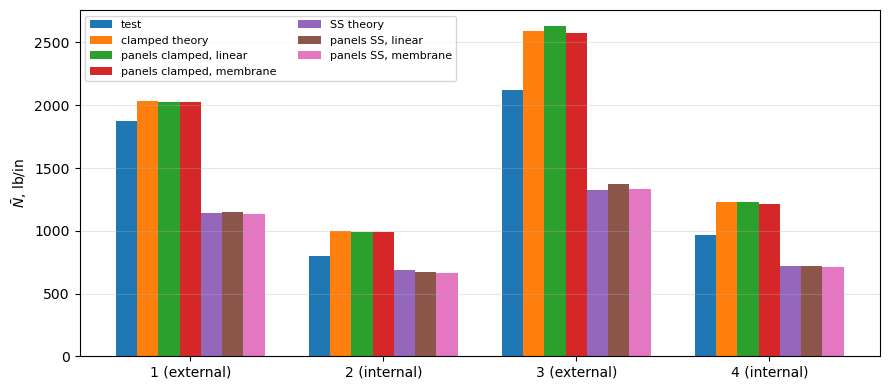

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
names = ['test', 'clamped theory', 'panels clamped, linear', 'panels clamped, membrane',
         'SS theory', 'panels SS, linear', 'panels SS, membrane']
width = 0.11
for k, name in enumerate(names):
    vals = []
    for cyl, row in TABLE_I.items():
        if name == 'test':
            vals.append(row[7])
        elif name == 'clamped theory':
            vals.append(row[8])
        elif name == 'SS theory':
            vals.append(row[9])
        else:
            vals.append(RES[(cyl, name[7:], FINAL)][0])
    ax.bar(np.arange(1, 5) + (k - 3)*width, vals, width, label=name)
ax.set_xticks(range(1, 5))
ax.set_xticklabels(['%d (%s)' % (cyl, row[0]) for cyl, row in TABLE_I.items()])
ax.set_ylabel(r'$\bar{N}$, lb/in')
ax.legend(fontsize=8, ncol=2)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## Buckling modes

Normal displacement $w$ of the skin of the half cylinder, unrolled, for the critical mode of the clamped analysis with the linear pre-buckling state; the dots mark the stringers.

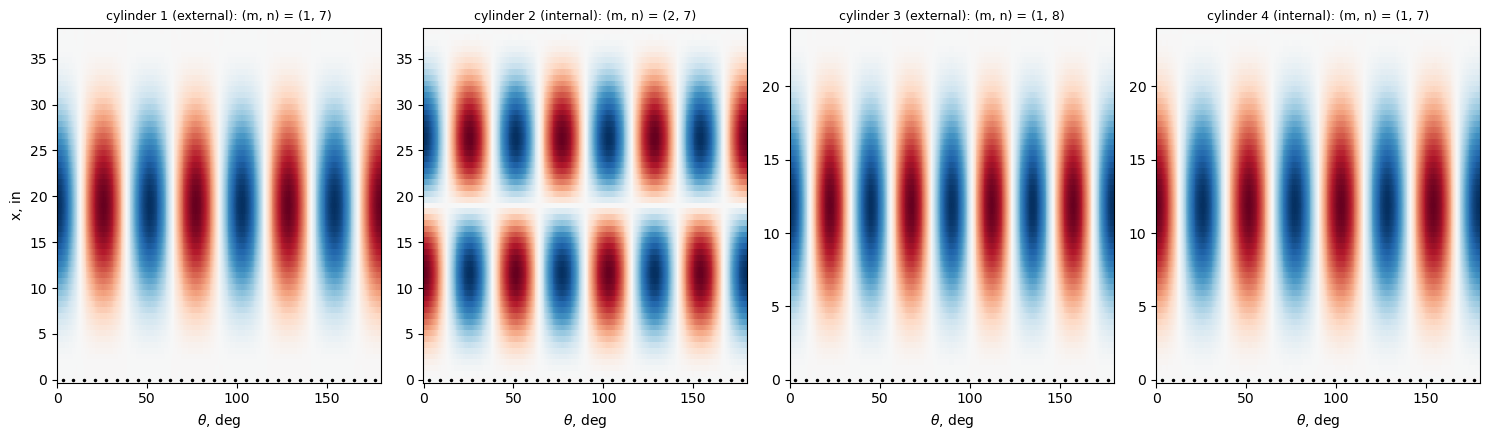

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4.5))
for ax, (cyl, row) in zip(axes, TABLE_I.items()):
    N, m, n, md, skin, c, _ = RES[(cyl, 'clamped, linear', FINAL)]
    x, th, w = bu.skin_w(md, c, skin, R_IN*IN)
    ax.pcolormesh(np.degrees(th), x/IN, (w/np.abs(w).max()).T, cmap='RdBu_r', shading='auto', vmin=-1, vmax=1)
    ax.plot(np.degrees((np.arange(NSTIFF//2) + 0.5)*2*np.pi/NSTIFF), np.zeros(NSTIFF//2), 'k.', ms=3)
    ax.set_title('cylinder %d (%s): (m, n) = (%d, %d)' % (cyl, row[0], m, n), fontsize=9)
    ax.set_xlabel(r'$\theta$, deg')
axes[0].set_ylabel('x, in')
plt.tight_layout()
plt.show()

## Discrete against smeared stringers: reference section and stringer spacing

The simply supported analysis with the membrane pre-buckling state and Eq. (15) of Block, Card and Mikulas (1965) hold the skin edges alike and use the same pre-buckling state (bullet *Edge conditions* of the discussion), so that their difference comes from the stringers: from the section given to the smeared theory, and from the way the two models represent the stringers. This section separates the two at the spacing of the tests and then varies the spacing.

**The section on each side.** The first table evaluates Eq. (15) for cylinder 4 with the drawn section of Fig. 2(b) (0.33 in deep including the skin, $J$ of a rectangle of Card and Jones), with the plate strip of the model (from the middle surface of the skin, $h_b = 0.33 - t/2$, twisting stiffness $G h_b t_b^3/3$ of a Kirchhoff plate strip), with the steps between them, and with $J = 0$. The second table puts three discrete loads against the two references: the simply supported analysis with the membrane state of this notebook, the regression value of the panels test of this case (`tests/multidomain/test_cylinder_blade_stiffened.py`: half of the length with symmetry conditions at $L/2$, $8 \times 6$ terms), and the bfsccylinder implementation (`bfsccylinder/notebooks/card1966_stiffened_cylinder_buckling.ipynb`). Only the comparison with the plate strip has the same section on both sides; the comparison with $\bar{N}_s$, and that of the bfsccylinder notebook with its smeared theory, put the plate strip of the discrete model against the drawn section.

In [11]:
t4, L4, side4, Ns4 = TABLE_I[4][1], TABLE_I[4][2], TABLE_I[4][0], TABLE_I[4][9]
HB4 = DEPTH - t4/2
drawn4 = section(t4, side4, DEPTH - t4, t4/2)
plate4 = section(t4, side4, HB4, 0., plate=True)
SECTIONS4 = {
    'Fig. 2(b), J of Card and Jones': drawn4,
    'Fig. 2(b), J of the plate strip': drawn4[:3] + (plate4[3],),
    'plate strip, J of the rectangle (Card and Jones)': plate4[:3] + (torsion_J(WIDTH, HB4),),
    'plate strip, J = h_b t_b^3/3 (the model)': plate4,
    'Fig. 2(b), J = 0': drawn4[:3] + (0.,),
    'plate strip, J = 0': plate4[:3] + (0.,),
}
SMEARED4 = {name: nx_ss(t4, L4, *s) for name, s in SECTIONS4.items()}
display(markdown_table(['cylinder 4, section', 'A_s, in^2', 'z_s, in', 'I_os, in^4', 'J, in^4',
                        'Eq. (15), lb/in (m, n)', 'vs N_s'],
                       [[name, '%.5f' % s[0], '%.4f' % s[1], '%.5e' % s[2], '%.4e' % s[3],
                         '%.1f (%d, %d)' % (SMEARED4[name][0], *SMEARED4[name][1]),
                         '%+.1f%%' % pct(SMEARED4[name][0], Ns4)] for name, s in SECTIONS4.items()]))
S_DRAWN = SMEARED4['Fig. 2(b), J of Card and Jones'][0]
S_PLATE = SMEARED4['plate strip, J = h_b t_b^3/3 (the model)'][0]
S_DRAWN_JP = SMEARED4['Fig. 2(b), J of the plate strip'][0]
print('plate strip against Fig. 2(b): %+.1f %%, of which J %+.1f %% and area, '
      'eccentricity and I_os %+.1f %%' % (pct(S_PLATE, S_DRAWN), pct(S_DRAWN_JP, S_DRAWN),
                                          pct(S_PLATE, S_DRAWN_JP)))
# discrete values of the simply supported analysis with the membrane state, cylinder 4
N_PANELS = RES[(4, 'SS, membrane', FINAL)][0]
# regression value of tests/multidomain/test_cylinder_blade_stiffened.py (half length
# with symmetry at L/2), 126130.9 N/m
N_TEST = 126130.9*IN/LBF
N_BFSC = BFSC[4][1]
display(markdown_table(['discrete model', 'N, lb/in', 'vs Eq. (15), plate strip with J = h_b t_b^3/3',
                        'vs Eq. (15), Fig. 2(b)', 'vs N_s'],
                       [[name, '%.1f' % N, '%+.1f%%' % pct(N, S_PLATE), '%+.1f%%' % pct(N, S_DRAWN),
                         '%+.1f%%' % pct(N, Ns4)]
                        for name, N in (('panels, this notebook', N_PANELS),
                                        ('panels, test (half length)', N_TEST),
                                        ('bfsccylinder notebook', N_BFSC))]))

| cylinder 4, section | A_s, in^2 | z_s, in | I_os, in^4 | J, in^4 | Eq. (15), lb/in (m, n) | vs N_s |
|---|---|---|---|---|---|---|
| Fig. 2(b), J of Card and Jones | 0.02929 | -0.1650 | 1.02017e-03 | 7.3363e-05 | 722.8 (1, 6) | +0.1% |
| Fig. 2(b), J of the plate strip | 0.02929 | -0.1650 | 1.02017e-03 | 9.6135e-05 | 758.6 (1, 6) | +5.1% |
| plate strip, J of the rectangle (Card and Jones) | 0.03065 | -0.1580 | 1.02026e-03 | 7.7621e-05 | 742.1 (1, 6) | +2.8% |
| plate strip, J = h_b t_b^3/3 (the model) | 0.03065 | -0.1580 | 1.02026e-03 | 9.6135e-05 | 771.2 (1, 6) | +6.8% |
| Fig. 2(b), J = 0 | 0.02929 | -0.1650 | 1.02017e-03 | 0.0000e+00 | 601.8 (1, 7) | -16.6% |
| plate strip, J = 0 | 0.03065 | -0.1580 | 1.02026e-03 | 0.0000e+00 | 609.2 (1, 7) | -15.6% |

plate strip against Fig. 2(b): +6.7 %, of which J +4.9 % and area, eccentricity and I_os +1.7 %


| discrete model | N, lb/in | vs Eq. (15), plate strip with J = h_b t_b^3/3 | vs Eq. (15), Fig. 2(b) | vs N_s |
|---|---|---|---|---|
| panels, this notebook | 712.9 | -7.6% | -1.4% | -1.3% |
| panels, test (half length) | 720.2 | -6.6% | -0.4% | -0.2% |
| bfsccylinder notebook | 723.0 | -6.2% | +0.0% | +0.1% |

**Separating the differences at the spacing of the tests.** For the same section, the discrete model differs from Eq. (15) in three respects, each of which `bu.buckling_membrane` can switch off:

- the kinematics of the skin: Sanders-Koiter (`cylshell_clpt_sanders`) in the model, "the usual Donnell-type assumptions" in the smeared theory (Block, Card and Mikulas 1965, p. 5); `skin_model='cylshell_clpt_donnell'` gives the Donnell skin;
- the load term of the stringers: in Eq. (9) of Block, Card and Mikulas (p. 8) the change in potential energy of the load is $\bar{N}_x w_{,x}^2$, with $\bar{N}_x$ "obtained by considering the shell and stringers to be loaded with a uniform normal stress", so that the stringer load acts on the radial displacement only. The blades of `plate_clpt_gl` carry their load $N_{xx}$ on the three displacements of the blade: the radial one (`v` of the blade), the axial one, and the out-of-plane one (`w` of the blade), which is the circumferential displacement of the stringer section: the circumferential displacement of the skin at the root plus the rotation of the section times the distance from the skin. `blade_lateral_kG=False` removes this last term ("lateral term" below) from the geometric stiffness of the blades;
- the twisting of the stringers: Eq. (6) of Block, Card and Mikulas (p. 7) adds the energy $G_s J_s w_{,xy}^2/d$ "as an approximation", for a stringer that "twists in a fashion so that its angle of twist is equal to the angle of twist of the shell", and averages it over the circumference, "hence, discreteness of the stringers is ignored" (p. 7); each blade of the model twists as a plate strip whose root follows the rotation of the skin. `blade_D66_factor=0` removes the twisting stiffness of the blades; these models are compared with Eq. (15) with $J = 0$.

The simply supported ends of the blades hold only their radial displacement; `bc='SSW'` also holds their circumferential displacement along the end edges, as the stringer ends of the bfsccylinder implementation do. Each model is computed with the two finest numbers of terms of the convergence study.

In [12]:
DON = 'cylshell_clpt_donnell'
VARIANTS = [
    ('Sanders skin (the model above)', dict(), 'plate strip, J = h_b t_b^3/3 (the model)'),
    ('Donnell skin', dict(skin_model=DON), 'plate strip, J = h_b t_b^3/3 (the model)'),
    ('Donnell skin, no lateral term', dict(skin_model=DON, blade_lateral_kG=False),
     'plate strip, J = h_b t_b^3/3 (the model)'),
    ('Donnell skin, no lateral term, blade ends held circumferentially',
     dict(skin_model=DON, blade_lateral_kG=False, bc='SSW'), 'plate strip, J = h_b t_b^3/3 (the model)'),
    ('Sanders skin, no twisting', dict(blade_D66_factor=0.), 'plate strip, J = 0'),
    ('Donnell skin, no twisting', dict(skin_model=DON, blade_D66_factor=0.), 'plate strip, J = 0'),
    ('Donnell skin, no twisting, no lateral term',
     dict(skin_model=DON, blade_D66_factor=0., blade_lateral_kG=False), 'plate strip, J = 0'),
]


def cyl4_ss(nstiff, level, bc='SS', **kw):
    # cylinder 4, simply supported, membrane state; blades of constant height HB4
    # and thickness WIDTH*60/nstiff; lowest general mode (m <= 3, n <= 12) and lowest mode
    tb = WIDTH*NSTIFF/nstiff
    P, modes, md, skin, dt = bu.buckling_membrane(R_IN*IN, t4*IN, L4*IN, E, NU, tb*IN, HB4*IN,
                                                  side4, bc, *level, nstiff=nstiff, **kw)
    N = P/LBF/(2*np.pi*R_IN)
    allm = [(lam/modes[0][0]*N, m, n) for lam, m, n, c in modes]
    general = [mode for mode in allm if mode[1] <= 3 and mode[2] <= 12]
    return general[0], allm[0], md.get_size(), dt


AT60 = {}
rows = []
for name, kw, ref in VARIANTS:
    prev = None
    for level in LEVELS[-2:]:
        gen, low, size, dt = cyl4_ss(NSTIFF, level, **kw)
        AT60[name] = gen
        rows.append([name, '%d, %d, %d' % level, size, '%.0f' % dt, '%.1f (%d, %d)' % gen,
                     '-' if prev is None else '%+.2f%%' % pct(gen[0], prev),
                     '%.1f' % SMEARED4[ref][0], '%+.1f%%' % pct(gen[0], SMEARED4[ref][0])])
        prev = gen[0]
display(markdown_table(['discrete model, cylinder 4, SS, membrane', 'm_x, n_y, n_b', 'dofs', 'time, s',
                        'N, lb/in (m, n)', 'change', 'Eq. (15), same section', 'difference'], rows))

| discrete model, cylinder 4, SS, membrane | m_x, n_y, n_b | dofs | time, s | N, lb/in (m, n) | change | Eq. (15), same section | difference |
|---|---|---|---|---|---|---|---|
| Sanders skin (the model above) | 18, 8, 5 | 21060 | 8 | 713.8 (1, 6) | - | 771.2 | -7.4% |
| Sanders skin (the model above) | 22, 10, 6 | 31680 | 16 | 712.9 (1, 6) | -0.14% | 771.2 | -7.6% |
| Donnell skin | 18, 8, 5 | 21060 | 8 | 731.6 (1, 6) | - | 771.2 | -5.1% |
| Donnell skin | 22, 10, 6 | 31680 | 16 | 730.6 (1, 6) | -0.14% | 771.2 | -5.3% |
| Donnell skin, no lateral term | 18, 8, 5 | 21060 | 8 | 758.7 (1, 6) | - | 771.2 | -1.6% |
| Donnell skin, no lateral term | 22, 10, 6 | 31680 | 17 | 757.4 (1, 6) | -0.16% | 771.2 | -1.8% |
| Donnell skin, no lateral term, blade ends held circumferentially | 18, 8, 5 | 21060 | 9 | 766.6 (1, 6) | - | 771.2 | -0.6% |
| Donnell skin, no lateral term, blade ends held circumferentially | 22, 10, 6 | 31680 | 16 | 766.6 (1, 6) | -0.00% | 771.2 | -0.6% |
| Sanders skin, no twisting | 18, 8, 5 | 21060 | 9 | 573.0 (1, 7) | - | 609.2 | -5.9% |
| Sanders skin, no twisting | 22, 10, 6 | 31680 | 19 | 573.0 (1, 7) | -0.00% | 609.2 | -5.9% |
| Donnell skin, no twisting | 18, 8, 5 | 21060 | 9 | 587.2 (1, 7) | - | 609.2 | -3.6% |
| Donnell skin, no twisting | 22, 10, 6 | 31680 | 22 | 587.2 (1, 7) | -0.00% | 609.2 | -3.6% |
| Donnell skin, no twisting, no lateral term | 18, 8, 5 | 21060 | 9 | 609.3 (1, 7) | - | 609.2 | +0.0% |
| Donnell skin, no twisting, no lateral term | 22, 10, 6 | 31680 | 22 | 609.3 (1, 7) | -0.00% | 609.2 | +0.0% |

**Stringer spacing.** The number of stringers $n_s$ of cylinder 4 is varied from 30 to 240, from twice to a quarter of the spacing $b = 2\pi R/n_s = 1.00$ in of the tests, at a constant total stringer area: the blade keeps its height $h_b$, and its thickness is $t_b = 0.097 \times 60/n_s$ in. The stringer terms of Eq. (15) per unit circumference, $E A_s/d$, $E A_s \bar{z}_s/d$ and $E I_{os}/d$ ($d = b$, the stringer spacing), are then the same at every point, and only the twisting term $G J/d$ changes, with $J = h_b t_b^3/3$, as $b^2$. The smeared theory and the discrete model use the same plate strip at every point. The spacing is given as $b/\sqrt{R t}$ and as $Z_b = b^2 \sqrt{1 - \nu^2}/(R t)$, the curvature parameter that Batdorf (1947, Fig. 11 and p. 11) uses for a curved panel of width $b$, here the skin between two stringers. Four models of the previous table are computed at each point with the two finest numbers of terms (the change between them is given); the lowest general-instability mode (at most three axial half-waves, $n \le 12$) is compared with the minimum of Eq. (15) over $(m, n)$, and the lowest mode of the model is given where it is another one.

S. B. Batdorf, *A simplified method of elastic-stability analysis for thin cylindrical shells*, NACA Report 874, 1947 (NTRS 19930091945).

In [13]:
NS_STUDY = [30, 40, 60, 90, 120, 180, 240]
STUDY_VARIANTS = VARIANTS[:3] + VARIANTS[-1:]
SPACING = {}
rows = []
for ns in NS_STUDY:
    tb = WIDTH*NSTIFF/ns
    b = 2*np.pi*R_IN/ns
    sp = section(t4, side4, HB4, 0., plate=True, width=tb)
    sm = {'plate strip, J = h_b t_b^3/3 (the model)': nx_ss(t4, L4, *sp, nstiff=ns),
          'plate strip, J = 0': nx_ss(t4, L4, *sp[:3], 0., nstiff=ns)}
    SPACING[(ns, 'smeared')] = sm
    for name, kw, ref in STUDY_VARIANTS:
        prev = None
        for level in LEVELS[-2:]:
            gen, low, size, dt = cyl4_ss(ns, level, **kw)
            change = '-' if prev is None else '%+.2f%%' % pct(gen[0], prev)
            prev = gen[0]
        SPACING[(ns, name)] = gen
        rows.append([ns, '%.3f' % b, '%.2f' % (b/np.sqrt(R_IN*t4)),
                     '%.2f' % (b**2/(R_IN*t4)*np.sqrt(1 - NU**2)), '%.4f' % tb, name,
                     '%.1f (%d, %d)' % gen, change,
                     '%.1f (%d, %d)' % (sm[ref][0], *sm[ref][1]), '%.3f' % (gen[0]/sm[ref][0]),
                     '-' if low == gen else '%.1f (%d, %d)' % low])
display(markdown_table(['n_s', 'b, in', 'b/sqrt(R t)', 'Z_b', 't_b, in', 'discrete model',
                        'N, lb/in (m, n)', 'change, last level', 'Eq. (15), same section',
                        'discrete/smeared', 'lowest mode if not general'], rows))

| n_s | b, in | b/sqrt(R t) | Z_b | t_b, in | discrete model | N, lb/in (m, n) | change, last level | Eq. (15), same section | discrete/smeared | lowest mode if not general |
|---|---|---|---|---|---|---|---|---|---|---|
| 30 | 2.000 | 3.87 | 14.17 | 0.1940 | Sanders skin (the model above) | 923.8 (1, 6) | -0.35% | 1223.9 (1, 6) | 0.755 | - |
| 30 | 2.000 | 3.87 | 14.17 | 0.1940 | Donnell skin | 953.8 (1, 6) | -0.36% | 1223.9 (1, 6) | 0.779 | - |
| 30 | 2.000 | 3.87 | 14.17 | 0.1940 | Donnell skin, no lateral term | 979.7 (1, 6) | -0.37% | 1223.9 (1, 6) | 0.800 | - |
| 30 | 2.000 | 3.87 | 14.17 | 0.1940 | Donnell skin, no twisting, no lateral term | 607.9 (1, 7) | -0.00% | 609.2 (1, 7) | 0.998 | - |
| 40 | 1.500 | 2.90 | 7.97 | 0.1455 | Sanders skin (the model above) | 838.2 (1, 6) | -0.32% | 959.8 (1, 6) | 0.873 | - |
| 40 | 1.500 | 2.90 | 7.97 | 0.1455 | Donnell skin | 863.2 (1, 6) | -0.33% | 959.8 (1, 6) | 0.899 | - |
| 40 | 1.500 | 2.90 | 7.97 | 0.1455 | Donnell skin, no lateral term | 892.2 (1, 6) | -0.35% | 959.8 (1, 6) | 0.930 | - |
| 40 | 1.500 | 2.90 | 7.97 | 0.1455 | Donnell skin, no twisting, no lateral term | 609.2 (1, 7) | -0.00% | 609.2 (1, 7) | 1.000 | - |
| 60 | 1.000 | 1.93 | 3.54 | 0.0970 | Sanders skin (the model above) | 712.9 (1, 6) | -0.14% | 771.2 (1, 6) | 0.924 | - |
| 60 | 1.000 | 1.93 | 3.54 | 0.0970 | Donnell skin | 730.6 (1, 6) | -0.14% | 771.2 (1, 6) | 0.947 | - |
| 60 | 1.000 | 1.93 | 3.54 | 0.0970 | Donnell skin, no lateral term | 757.4 (1, 6) | -0.16% | 771.2 (1, 6) | 0.982 | - |
| 60 | 1.000 | 1.93 | 3.54 | 0.0970 | Donnell skin, no twisting, no lateral term | 609.3 (1, 7) | -0.00% | 609.2 (1, 7) | 1.000 | - |
| 90 | 0.667 | 1.29 | 1.57 | 0.0647 | Sanders skin (the model above) | 644.8 (1, 6) | -0.03% | 687.3 (1, 6) | 0.938 | - |
| 90 | 0.667 | 1.29 | 1.57 | 0.0647 | Donnell skin | 658.6 (1, 6) | -0.03% | 687.3 (1, 6) | 0.958 | - |
| 90 | 0.667 | 1.29 | 1.57 | 0.0647 | Donnell skin, no lateral term | 683.5 (1, 6) | -0.05% | 687.3 (1, 6) | 0.994 | - |
| 90 | 0.667 | 1.29 | 1.57 | 0.0647 | Donnell skin, no twisting, no lateral term | 609.3 (1, 7) | -0.00% | 609.2 (1, 7) | 1.000 | - |
| 120 | 0.500 | 0.97 | 0.89 | 0.0485 | Sanders skin (the model above) | 619.0 (1, 7) | -0.01% | 658.0 (1, 6) | 0.941 | - |
| 120 | 0.500 | 0.97 | 0.89 | 0.0485 | Donnell skin | 632.1 (1, 6) | -0.01% | 658.0 (1, 6) | 0.961 | - |
| 120 | 0.500 | 0.97 | 0.89 | 0.0485 | Donnell skin, no lateral term | 656.2 (1, 6) | -0.02% | 658.0 (1, 6) | 0.997 | - |
| 120 | 0.500 | 0.97 | 0.89 | 0.0485 | Donnell skin, no twisting, no lateral term | 609.2 (1, 7) | -0.00% | 609.2 (1, 7) | 1.000 | - |
| 180 | 0.333 | 0.64 | 0.39 | 0.0323 | Sanders skin (the model above) | 593.7 (1, 7) | -0.00% | 632.1 (1, 7) | 0.939 | - |
| 180 | 0.333 | 0.64 | 0.39 | 0.0323 | Donnell skin | 608.8 (1, 7) | -0.00% | 632.1 (1, 7) | 0.963 | - |
| 180 | 0.333 | 0.64 | 0.39 | 0.0323 | Donnell skin, no lateral term | 631.2 (1, 7) | -0.01% | 632.1 (1, 7) | 0.999 | - |
| 180 | 0.333 | 0.64 | 0.39 | 0.0323 | Donnell skin, no twisting, no lateral term | 609.2 (1, 7) | -0.00% | 609.2 (1, 7) | 1.000 | - |
| 240 | 0.250 | 0.48 | 0.22 | 0.0243 | Sanders skin (the model above) | 584.7 (1, 7) | -0.00% | 622.1 (1, 7) | 0.940 | - |
| 240 | 0.250 | 0.48 | 0.22 | 0.0243 | Donnell skin | 599.4 (1, 7) | -0.00% | 622.1 (1, 7) | 0.964 | - |
| 240 | 0.250 | 0.48 | 0.22 | 0.0243 | Donnell skin, no lateral term | 621.6 (1, 7) | -0.00% | 622.1 (1, 7) | 0.999 | - |
| 240 | 0.250 | 0.48 | 0.22 | 0.0243 | Donnell skin, no twisting, no lateral term | 609.2 (1, 7) | -0.00% | 609.2 (1, 7) | 1.000 | - |

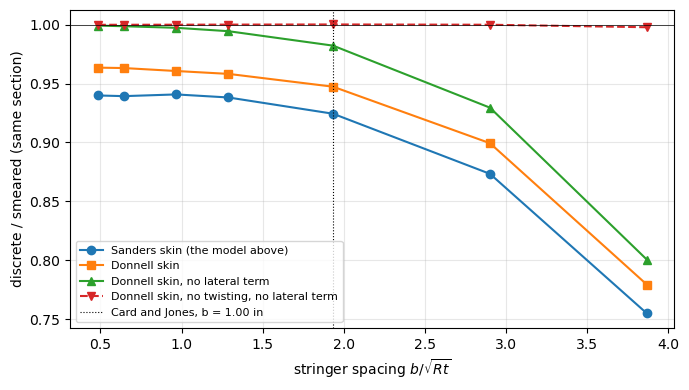

In [14]:
fig, ax = plt.subplots(figsize=(7, 4))
xs = [2*np.pi*R_IN/ns/np.sqrt(R_IN*t4) for ns in NS_STUDY]
for (name, kw, ref), style in zip(STUDY_VARIANTS, ['o-', 's-', '^-', 'v--']):
    ax.plot(xs, [SPACING[(ns, name)][0]/SPACING[(ns, 'smeared')][ref][0] for ns in NS_STUDY],
            style, label=name)
ax.axvline(1.00/np.sqrt(R_IN*t4), color='k', lw=0.8, ls=':', label='Card and Jones, b = 1.00 in')
ax.axhline(1., color='k', lw=0.5)
ax.set_xlabel(r'stringer spacing $b/\sqrt{R t}$')
ax.set_ylabel('discrete / smeared (same section)')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**What the two tables establish** (cylinder 4, simply supported ends, membrane pre-buckling state):

- *Reference section.* Eq. (15) for the plate strip of the model is 6.7 % above Eq. (15) for the drawn section of Fig. 2(b) (771.2 against 722.8 lb/in): 4.9 % from the twisting stiffness of the Kirchhoff plate strip, whose $J$ is 31 % above that of the drawn rectangle, and 1.7 % from the area, eccentricity and moment of inertia. The -7.6 % of this notebook (-6.6 % of the test) is measured against the same section. The -1.4 % against the drawn section, and the +0.0 % of the bfsccylinder notebook against its smeared theory, compare different sections: they are small because the 6.7 % of the section offsets the differences of the models.
- *Same section, spacing of the tests.* The -7.6 % is the sum of three parts: the Sanders skin against the Donnell skin of the theory (712.9 against 730.6 lb/in, -2.4 %), the lateral term (730.6 against 757.4 lb/in, -3.5 %) and the twisting of the blades (757.4 against 771.2 lb/in, -1.8 %; -0.6 % with the blade ends held circumferentially). Without the twisting stiffness on both sides, with the Donnell skin and without the lateral term, the discrete model reproduces Eq. (15) to 0.02 % (609.3 against 609.2 lb/in).
- *Spacing.* From $b/\sqrt{R t}$ = 0.48 to 3.87 at constant stringer area, the model without twisting stiffness, with the Donnell skin and without the lateral term, stays within 0.2 % of Eq. (15) with $J = 0$: over this range the discreteness of the stringers does not change the bending and extension part of the smeared theory. The lateral term (-2.6 % to -3.7 %) and the Sanders skin (-2.1 % to -3.1 %) depend little on the spacing. The twisting part grows with the spacing: the Donnell model without the lateral term is 0.1 % below Eq. (15) at a quarter and a third of the spacing of the tests, 0.3 % at half, 0.6 % at two thirds, 1.8 % at their spacing, 7.0 % at 1.5 times and 20 % at twice the spacing, where the twisting stiffness of the thick blade ($t_b/h_b = 0.61$) doubles the smeared load (1224 against 609 lb/in with $J = 0$). The model of this notebook is therefore 5.9 % to 6.2 % below Eq. (15) for spacings up to two thirds of that of the tests, 7.6 % at the spacing of the tests, 12.7 % at 1.5 times and 24.5 % at twice. In the bfsccylinder implementation of this study (`bfsccylinder/notebooks/card1966_stiffened_cylinder_buckling.ipynb`, same cylinder, spacings and sections) the model without twisting stiffness, with the Donnell skin and without the lateral term is 0.2 % to 0.4 % above Eq. (15) at every spacing (the change of its last mesh refinement is about 0.5 %), the lateral term is -2.7 % to -3.8 %, the Sanders skin -2.0 % to -3.2 %, and the twisting part -0.3 % at the spacing of the tests (its stringer ends are held circumferentially), -4.7 % at 1.5 times and -18 % at twice; its model is 6.3 % below Eq. (15) for the same section at the spacing of the tests (722.7 against 771.2 lb/in) and 5.4 % to 5.6 % below at the closer spacings.

## Discussion

- **Convergence.** With the last two numbers of terms the critical loads change by less than 0.15 %. With the coarsest model the clamped analysis with the linear pre-buckling state of the long cylinders 1 and 2 ($L/R = 4$) has too few axial terms for the boundary layers at the ends and is 12 % and 16 % low.
- **Section of the stringers.** Fig. 2(b) dimensions the total depth of the section, 0.33 in from the stringer tip to the skin surface opposite the stringer; the plate strips of the model go from the middle surface of the skin to the tip, $h_b = 0.33 - t/2$ in. With this section the simply supported smeared solution of Block, Card and Mikulas (1965, Eq. (15)) reproduces the four $\bar{N}_s$ of Card and Jones within 0.2 % (table of the section *Test data*): their theory used the drawn section. The area $A_t$ of Table I, by weighing, is 3 % to 6 % larger than this section with the doublers of the butt joints; the report does not explain the difference (the rivets of the joints are not counted), which is not part of the theory and is not modelled. With a stringer 0.33 in high above the skin surface Eq. (15) would be up to 10 % above $\bar{N}_s$, most for the external stringers, whose eccentricity raises the load most.
- **Smeared theory.** With the assumptions of Card and Jones (membrane pre-buckling state, clamped or simply supported ends), `panels` is within 1.0 % of their clamped theory $\bar{N}_c$ for the four cylinders and between -3.4 % and +0.6 % of the simply supported $\bar{N}_s$. These theoretical values are for the drawn section of Fig. 2(b), not for the plate strip of the model. Against Eq. (15) for the plate strip, the same section, the simply supported load of cylinder 4 is 7.6 % lower; the section *Discrete against smeared stringers* splits this into the Sanders skin against the Donnell skin of the theory (-2.4 %), the work of the blade load on the circumferential displacement of the stringer section, which Eq. (9) of Block, Card and Mikulas leaves out (-3.5 %), and the twisting of the discrete blades against the term $G_s J_s w_{,xy}^2/d$ of the theory (-1.8 %, -0.6 % with the blade ends held circumferentially), while the plate strip itself raises Eq. (15) by 6.7 % over the drawn section ($J$ of the Kirchhoff plate strip, 31 % above $J$ of the drawn rectangle, +4.9 %; area, eccentricity and moment of inertia +1.7 %). With the same section, without twisting stiffness, with the Donnell skin and without that load term, the discrete model reproduces Eq. (15) within 0.2 % for stringer spacings from a quarter to twice that of the tests ($b/\sqrt{R t}$ = 0.48 to 3.87); only the twisting part depends on the spacing, from -0.1 % at the closest spacings to -20 % at twice the spacing of the tests. The torsional stiffness $G_s J_s$ raises the loads of these integral cylinders by 10 % to 20 % (Card and Jones, p. 11).
- **The bfsccylinder implementation of this case**, with the same section and the same end conditions, gives critical loads 0.3 % to 0.5 % above those of `panels` for the clamped analyses and 0.7 % to 1.4 % above for the simply supported analysis (table above), and reproduces $\bar{N}_c$ within 0.6 % and $\bar{N}_s$ within 2.7 %. Both use Sanders-type kinematics for the skin and plate stringers tied to the skin with the rotation about the stringer axis continuous; they differ in the discretization (Ritz series against BFSC finite elements with cyclic symmetry), in the geometric stiffness of the blades (`plate_clpt_gl` includes the term $N_{xx} u_{,x}^2$) and, for the simply supported ends, in the stringer ends, which bfsccylinder also restrains circumferentially. For the same section, Eq. (15) for the plate strip of cylinder 4, the bfsccylinder model is 6.3 % below (722.7 against 771.2 lb/in) and this one 7.6 %; both split the same way (section *Discrete against smeared stringers*), and the difference between them is in the twisting part, -0.3 % there and -1.8 % here, -0.6 % with the blade ends held circumferentially as there.
- **Pre-buckling state.** The linear static pre-buckling state, with the bending of the skin near the restrained ends, raises the critical load by 0.1 % to 2.8 % above the membrane state, most for cylinder 3, in line with the conclusion of Card and Jones that a membrane pre-buckling state is sufficient for assessing the eccentricity effect (p. 11).
- **Edge conditions (Almroth 1966).** B. O. Almroth, *Influence of edge conditions on the stability of axially compressed cylindrical shells*, AIAA Journal 4(1) (1966) 134-140, https://doi.org/10.2514/3.3396, computed the classical buckling load of axially compressed unstiffened isotropic cylinders (Donnell equations) for eight sets of edge conditions (Eq. (9), p. 135). The paper treats no stiffeners, discrete or smeared, and gives no value for the difference between them; it bears on the comparison with the smeared theory only through the edges of the skin. With the membrane pre-buckling state, simple supports with $v = 0$, with either $u = 0$ or $N_x = 0$ (his cases S1 and S2), give a load "equal to or insignificantly higher than the classical buckling load" (p. 138), and only edges free in the circumferential direction, $N_{xy} = 0$ (S3 and S4), lower it, to about one half (Table 2, p. 137). The simply supported analysis with the membrane state and Eq. (15) both hold $v = w = 0$ with $N_x = 0$ at the edges of the skin, so these edge conditions do not explain their difference, which for cylinder 4 is -7.6 % against Eq. (15) for the plate strip of the model (713 against 771 lb/in) and is split in the section *Discrete against smeared stringers* (bullet *Smeared theory*). With the bending at restrained edges in the pre-buckling state (his "rigorous prebuckling analysis") Almroth's loads fall to 0.80 to 0.88 of the classical value for these simple supports and to 0.86 to 0.93 for clamped edges (Table 2, modes of $n$ = 8 to 88 waves), a reduction he finds too small to explain the difference between theory and tests, which he expects initial imperfections to explain (pp. 139-140); the stiffened cylinders here, buckling with $n$ = 5 to 8, gain 0.1 % to 2.8 % from the linear pre-buckling state instead (previous bullet).
- **Boundary conditions.** The clamped loads are 1.5 to 1.9 times the simply supported ones. The test loads lie between the two and 20 % to 63 % above the simply supported analysis of `panels` although imperfections can only lower them, which is why Card and Jones concluded that the test cylinders were more nearly clamped than simply supported (p. 11). The axial restraint of the clamped ends, with $u$ prescribed on the whole end section, contributes to the difference between the two conditions (Appendix B of the report).
- **Test against analysis.** The test loads are 79 % to 92 % of the clamped analysis of `panels`, as of the clamped theory of the report (Card and Jones give 70 % to 95 % for all twelve cylinders). Linear buckling of the perfect cylinder is an upper bound: the test loads are reduced by the initial imperfections, to which axially compressed cylinders are sensitive (the external cylinders buckled with a loud report and large diamond-shaped buckles, p. 8), by the two butt joints per cylinder with riveted doubler plates (p. 5), by the potting of the ends in a soft alloy, which is not a perfect clamp, and by the scatter of the skin thickness ($\pm 8$ % of the average, p. 5).
- **External against internal stringers.** The ratio of the external to the internal cylinder of the same length is 2.04 and 2.14 in `panels`, 2.04 and 2.12 in the clamped theory, and 2.35 and 2.20 in the tests: the discrete model reproduces the eccentricity effect that motivated the tests.
- **Wave numbers.** The clamped analysis gives one more circumferential wave than the tests ($n = 7$, 7, 8, 7 against 6, 6, 7, 6); the measured $n$ is a neighbouring mode, 7 % (cylinders 1 and 3) and 4 % (cylinder 2, mode $(1, 6)$) above the critical load, and more than 20 % for cylinder 4 (table above). The simply supported analysis gives the measured $n$ for cylinders 1, 3 and 4. Imperfections and the actual end restraint can select a neighbouring mode. Cylinder 1 developed two tiers of buckles in the test (p. 8); in `panels` its lowest mode with two axial half-waves, $(m, n) = (2, 8)$, is 9 % above the critical one. The critical mode of cylinder 2 has two axial half-waves in both analyses with clamped ends, as in the bfsccylinder implementation.
